### Begin

In [1]:
# env1 3.11.13
import pandas as pd
from pathlib import Path
import requests
import pandas as pd
import numpy as np
import joblib
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error
import matplotlib.pyplot as plt
import io
import zipfile




exports = Path("loadcurves/exports")

#### Load ERCOT

In [2]:
# from https://www.ercot.com/gridinfo/load/load_hist

# most likely in Central Time Zone (CT), needs conversion

ercot_native_2018 = pd.read_excel(exports / "Native_Load_2018.xlsx", sheet_name="Native Load Report")

In [3]:
ercot_native_2018.head()

,HourEnding,COAST,EAST,FWEST,NORTH,NCENT,SOUTH,SCENT,WEST,ERCOT
0,01/01/2018 01:00,11425.979115,1852.663959,2823.409245,1135.360907,18584.343617,3831.649454,9151.190703,1762.472684,50567.069682
1,01/01/2018 02:00,11408.418023,1850.169452,2809.745403,1136.630855,18524.141392,3988.271046,9144.993712,1754.718094,50617.087977
2,01/01/2018 03:00,11405.198365,1858.269586,2797.802576,1135.930264,18532.056616,4076.086451,9141.036615,1747.919615,50694.300087
3,01/01/2018 04:00,11450.560138,1879.623596,2807.793880,1146.069491,18647.444612,4154.939804,9157.956866,1755.203307,50999.591693
4,01/01/2018 05:00,11631.337459,1876.481320,2822.989206,1154.186967,19002.102222,4247.451523,9214.333628,1774.849690,51723.732017


#### ERCOT ORIGINAL

Loading ERCOT Excel file from: loadcurves/exports/Native_Load_2018.xlsx


Conversion Successful.
Timezone: datetime64[us, Etc/GMT+5]


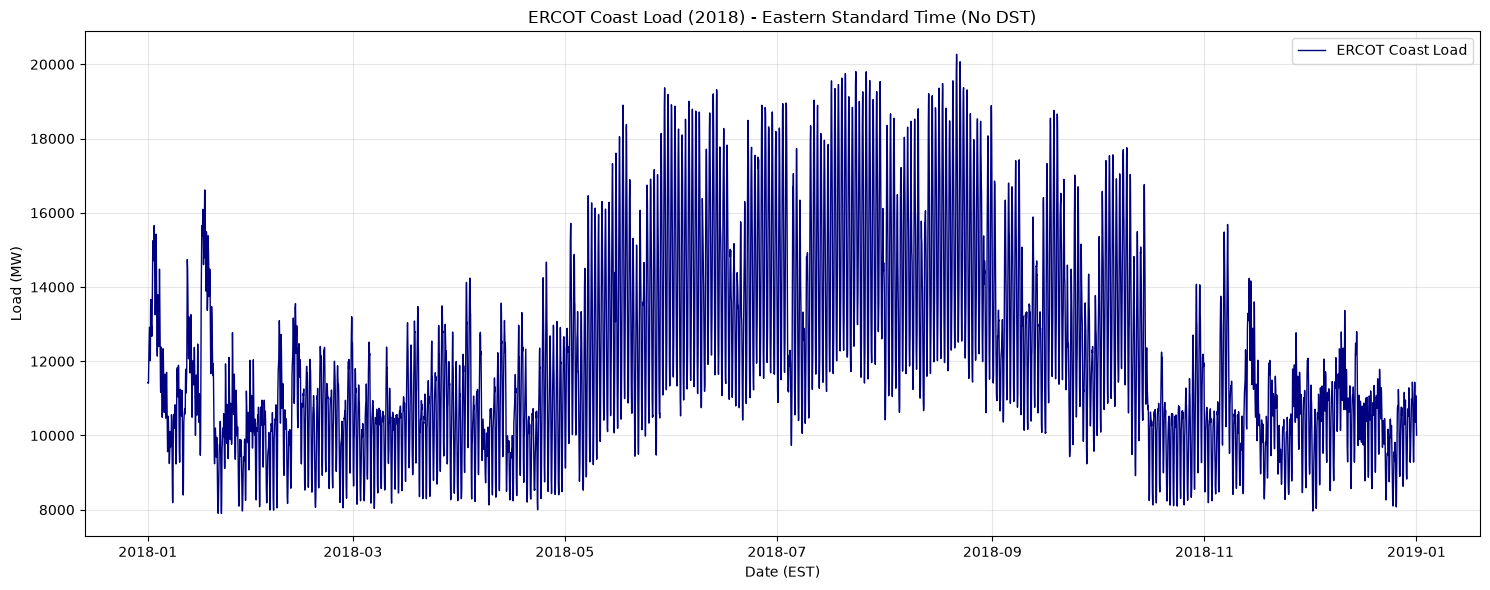

In [4]:
# --- 1. LOAD ERCOT DATA ---
file_path = exports / "Native_Load_2018.xlsx"
print(f"Loading ERCOT Excel file from: {file_path}")

ercot_df = pd.read_excel(file_path, sheet_name="Native Load Report")

# --- 2. PRECISE PARSING ---

# Ensure column is string
ercot_df['HourEnding'] = ercot_df['HourEnding'].astype(str)

# A. Extract DST Flag (The "Truth" Source)
# Create a boolean array: True = DST, False = Standard
is_dst_mask = ercot_df['HourEnding'].str.contains(' DST', regex=False)

# B. Clean the String 
# Remove " DST" so pandas can parse the date
ercot_df['HourEnding'] = ercot_df['HourEnding'].str.replace(' DST', '', regex=False)

# C. Handle "24:00"
# Identify rows that are 24:00
mask_24 = ercot_df['HourEnding'].str.contains('24:00')
# Replace with 00:00 temporarily
ercot_df['HourEnding'] = ercot_df['HourEnding'].str.replace('24:00', '00:00')

# D. Convert to Naive Datetime (Wall Clock Time)
naive_timestamps = pd.to_datetime(ercot_df['HourEnding'])

# E. Fix the "24:00" Date Shift (Add 1 Day)
naive_timestamps.loc[mask_24] += pd.Timedelta(days=1)

# --- 3. TIMEZONE LOCALIZATION ---

# We pass the boolean mask to 'ambiguous'. 
# This tells pandas: "For every row, use this specific True/False value to decide if it is DST."
ercot_df['date_time'] = naive_timestamps.dt.tz_localize(
    'US/Central', 
    ambiguous=is_dst_mask, 
    nonexistent='shift_forward'
)

# Set the clean index
ercot_df = ercot_df.set_index('date_time')

# --- 4. CONVERT TO EST (No DST) ---
# Convert to 'Etc/GMT+5' (Fixed UTC-5, which is EST year-round)
ercot_df_est = ercot_df.tz_convert('Etc/GMT+5')

print("Conversion Successful.")
print(f"Timezone: {ercot_df_est.index.dtype}")

# --- 5. PLOT ---
plt.figure(figsize=(15, 6))

plt.plot(ercot_df_est.index, ercot_df_est['COAST'], 
         color='navy', linewidth=1, label='ERCOT Coast Load')

plt.title("ERCOT Coast Load (2018) - Eastern Standard Time (No DST)")
plt.xlabel("Date (EST)")
plt.ylabel("Load (MW)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

#### Res, Com vs ERCOT

Loading estimated profiles...


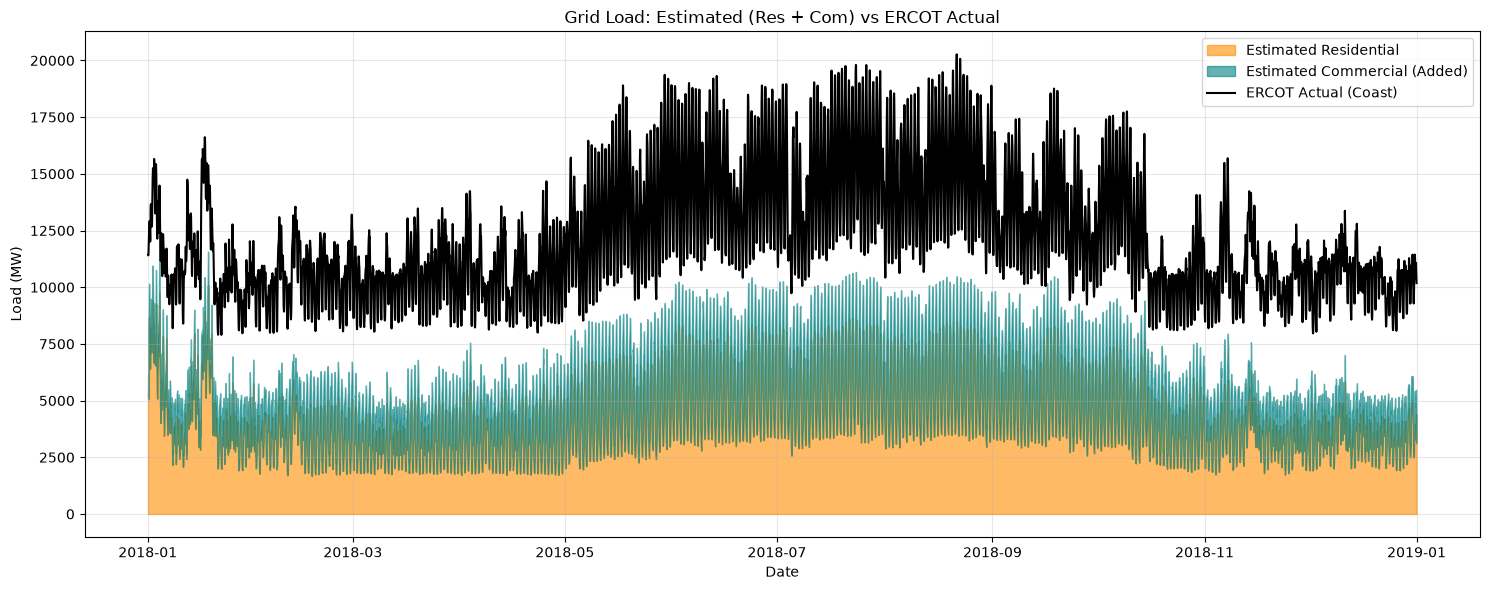

----------------------------------------
Peak Actual (ERCOT):    20,269.85 MW
Peak Estimated (Total): 11,559.54 MW
  -> Peak Res Portion:  10,084.05 MW
  -> Peak Com Portion:  2,534.72 MW
----------------------------------------


In [5]:
# --- 1. LOAD ESTIMATED PROFILES ---
res_path = exports / "final_bus_load_profiles_8760_featureeng.csv"
com_path = exports / "final_comstock_bus_load_profiles_8760_featureeng.csv"

print("Loading estimated profiles...")
res_profiles_df = pd.read_csv(res_path, index_col=0, parse_dates=True)
com_profiles_df = pd.read_csv(com_path, index_col=0, parse_dates=True)

# --- 2. SUM ACROSS ALL BUSES (Convert to MW) ---
total_res_mw = res_profiles_df.sum(axis=1) / 1000
total_com_mw = com_profiles_df.sum(axis=1) / 1000
total_est_load_mw = total_res_mw + total_com_mw

# --- 3. ALIGN TIMEZONES WITH ERCOT ---
ercot_plot_data = ercot_df_est['COAST'].copy()
ercot_plot_data.index = ercot_plot_data.index.tz_localize(None)

common_start = max(ercot_plot_data.index.min(), total_est_load_mw.index.min())
common_end = min(ercot_plot_data.index.max(), total_est_load_mw.index.max())

y_actual = ercot_plot_data.loc[common_start:common_end]
y_est_total = total_est_load_mw.loc[common_start:common_end]
y_est_res = total_res_mw.loc[common_start:common_end]

# --- 4. PLOT (STACKED AREA) ---
plt.figure(figsize=(15, 6))

# Plot A: Residential (Filled from 0 up to Res)
plt.fill_between(y_est_res.index, 0, y_est_res, 
                 color='darkorange', alpha=0.6, label='Estimated Residential')

# Plot B: Commercial (Filled from Res up to Total)
plt.fill_between(y_est_total.index, y_est_res, y_est_total, 
                 color='teal', alpha=0.6, label='Estimated Commercial (Added)')

# Plot C: ERCOT Actual (Solid Line over the top)
plt.plot(y_actual.index, y_actual, 
         color='black', linewidth=1.5, label='ERCOT Actual (Coast)')

# Formatting
plt.title("Grid Load: Estimated (Res + Com) vs ERCOT Actual")
plt.xlabel("Date")
plt.ylabel("Load (MW)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

# --- 5. PRINT STATS ---
print("-" * 40)
print(f"Peak Actual (ERCOT):    {y_actual.max():,.2f} MW")
print(f"Peak Estimated (Total): {y_est_total.max():,.2f} MW")
print(f"  -> Peak Res Portion:  {y_est_res.max():,.2f} MW")
print(f"  -> Peak Com Portion:  {total_com_mw.loc[common_start:common_end].max():,.2f} MW")
print("-" * 40)

**Note (2026-08-30): switched to the `_featureeng` pipeline output.** This notebook previously read the
original `final_bus_load_profiles_8760.csv` / `final_comstock_bus_load_profiles_8760.csv` — the pre-fix
files (wrong weather station, leaky train/test split). The pipeline has since gone through 3 real
improvements (see project memory: weather-station fix, temporal-leakage fix, LightGBM + lag/rolling
temperature features), landing on `_featureeng` as the current best version. The RES_SCALE/COM_SCALE
calibration below was never re-run after those fixes — it's being redone in this pass.

#### Fitting

In [6]:
# ==========================================
# --- 1. CALIBRATION PARAMETERS ---
# ==========================================
IND_BASE_MW = 4500.0   # Flat industrial/baseload in MW
RES_SCALE = 1.0        # Multiplier for Residential load
COM_SCALE = 1.0        # Multiplier for Commercial load
# ==========================================

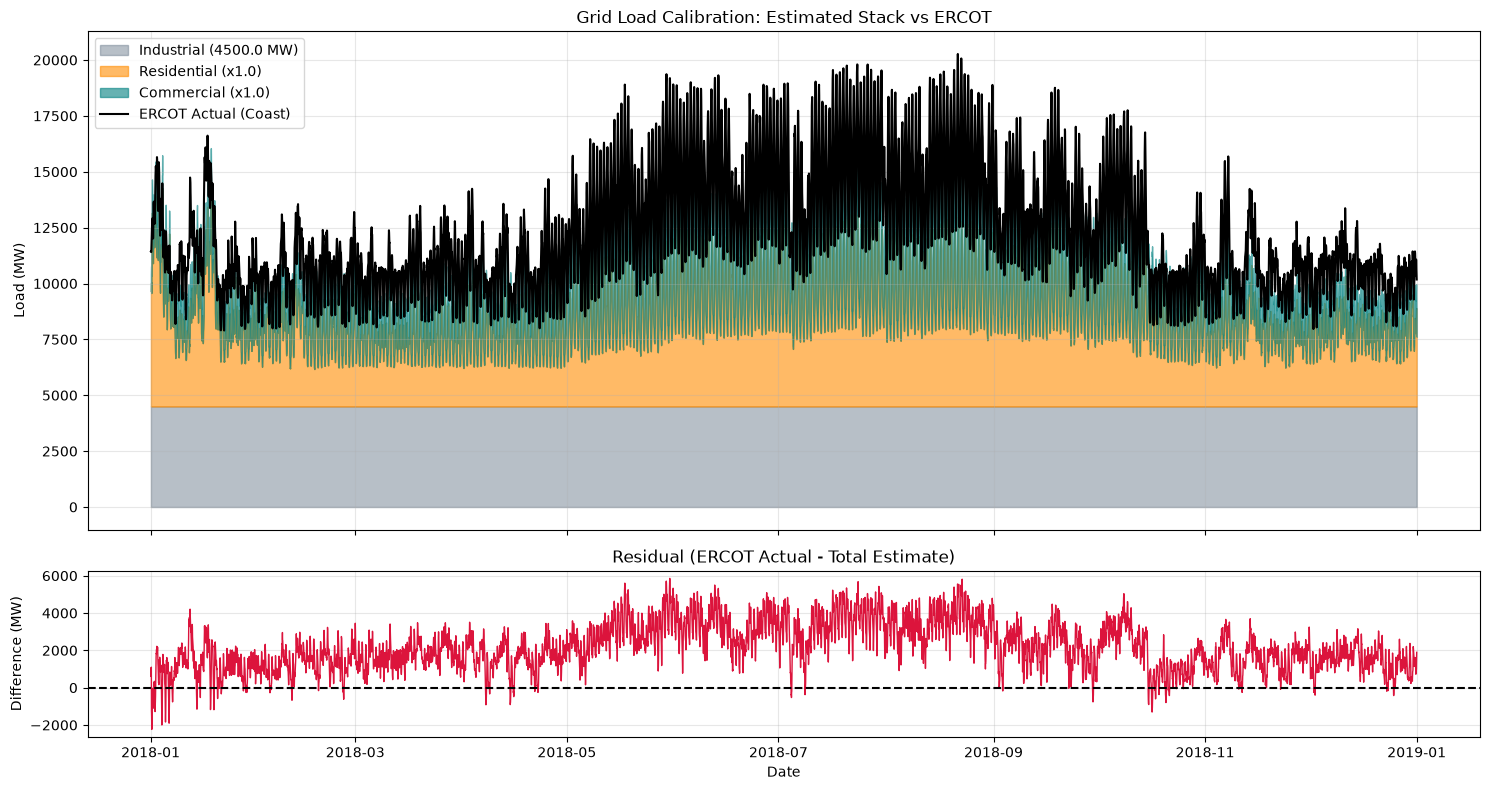


LOAD CALIBRATION STATISTICS
--- PEAKS ---
ERCOT Actual Peak:      20,269.85 MW
Total Estimated Peak:   16,059.54 MW
  -> Industrial Peak:   4,500.00 MW (Flat)
  -> Residential Peak:  10,084.05 MW (Scale: x1.0)
  -> Commercial Peak:   2,534.72 MW (Scale: x1.0)
---------------------------------------------
--- ERROR METRICS ---
Pearson Correlation:    0.9020  (Shape match: 1.0 is perfect)
Mean Absolute Error:    2,184.39 MW  (Avg gap)
Root Mean Square Error: 2,486.39 MW
Max Under-prediction:   5,856.23 MW  (Est. too low)
Max Over-prediction:    -2,234.67 MW  (Est. too high)


In [7]:
# --- 2. LOAD DATA ---
res_path = exports / "final_bus_load_profiles_8760_featureeng.csv"
com_path = exports / "final_comstock_bus_load_profiles_8760_featureeng.csv"

# Read CSVs (assuming already run/in memory, but here for completeness)
res_profiles_df = pd.read_csv(res_path, index_col=0, parse_dates=True)
com_profiles_df = pd.read_csv(com_path, index_col=0, parse_dates=True)

# --- 3. APPLY SCALING & SUM ACROSS BUSES (MW) ---
total_res_mw = (res_profiles_df.sum(axis=1) / 1000) * RES_SCALE
total_com_mw = (com_profiles_df.sum(axis=1) / 1000) * COM_SCALE

# --- 4. ALIGN TIMEZONES WITH ERCOT ---
ercot_plot_data = ercot_df_est['COAST'].copy()
ercot_plot_data.index = ercot_plot_data.index.tz_localize(None)

common_start = max(ercot_plot_data.index.min(), total_res_mw.index.min())
common_end = min(ercot_plot_data.index.max(), total_res_mw.index.max())

y_actual = ercot_plot_data.loc[common_start:common_end]
y_res = total_res_mw.loc[common_start:common_end]
y_com = total_com_mw.loc[common_start:common_end]

# Create the flat Industrial series
y_ind = pd.Series(IND_BASE_MW, index=y_res.index)

# --- 5. CALCULATE STACK & ERROR ---
layer1_top = y_ind
layer2_top = layer1_top + y_res
layer3_top = layer2_top + y_com  # This is the Total Estimated Load

# The Error: Positive means ERCOT is higher (we underpredicted)
# Negative means our estimate is higher (we overpredicted)
error_mw = y_actual - layer3_top 

# --- 6. PLOT (TWO PANELS) ---
# Create a figure with 2 subplots (Height ratio 3:1)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 8), gridspec_kw={'height_ratios': [3, 1]}, sharex=True)

# -- TOP PANEL: Stacked Area --
ax1.fill_between(y_ind.index, 0, layer1_top, color='slategray', alpha=0.5, label=f'Industrial ({IND_BASE_MW} MW)')
ax1.fill_between(y_res.index, layer1_top, layer2_top, color='darkorange', alpha=0.6, label=f'Residential (x{RES_SCALE})')
ax1.fill_between(y_com.index, layer2_top, layer3_top, color='teal', alpha=0.6, label=f'Commercial (x{COM_SCALE})')

ax1.plot(y_actual.index, y_actual, color='black', linewidth=1.5, label='ERCOT Actual (Coast)')

ax1.set_title("Grid Load Calibration: Estimated Stack vs ERCOT")
ax1.set_ylabel("Load (MW)")
ax1.legend(loc='upper left')
ax1.grid(True, alpha=0.3)

# -- BOTTOM PANEL: Residual (Error) --
# Plot the error line
ax2.plot(error_mw.index, error_mw, color='crimson', linewidth=1)
# Draw a bold line at Zero (Perfect Match)
ax2.axhline(0, color='black', linewidth=1.5, linestyle='--')

ax2.set_title("Residual (ERCOT Actual - Total Estimate)")
ax2.set_xlabel("Date")
ax2.set_ylabel("Difference (MW)")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# --- 7. PRINT STATS ---
# Calculate some helpful error metrics
mean_abs_error = error_mw.abs().mean()
rmse = np.sqrt((error_mw**2).mean())

# Calculate Pearson Correlation Coefficient (measuring the linear relationship/shape match)
pearson_corr = y_actual.corr(layer3_top)

print("\n" + "="*45)
print("LOAD CALIBRATION STATISTICS")
print("="*45)
print("--- PEAKS ---")
print(f"ERCOT Actual Peak:      {y_actual.max():,.2f} MW")
print(f"Total Estimated Peak:   {layer3_top.max():,.2f} MW")
print(f"  -> Industrial Peak:   {y_ind.max():,.2f} MW (Flat)")
print(f"  -> Residential Peak:  {y_res.max():,.2f} MW (Scale: x{RES_SCALE})")
print(f"  -> Commercial Peak:   {y_com.max():,.2f} MW (Scale: x{COM_SCALE})")
print("-" * 45)
print("--- ERROR METRICS ---")
print(f"Pearson Correlation:    {pearson_corr:.4f}  (Shape match: 1.0 is perfect)")
print(f"Mean Absolute Error:    {mean_abs_error:,.2f} MW  (Avg gap)")
print(f"Root Mean Square Error: {rmse:,.2f} MW")
print(f"Max Under-prediction:   {error_mw.max():,.2f} MW  (Est. too low)")
print(f"Max Over-prediction:    {error_mw.min():,.2f} MW  (Est. too high)")
print("="*45)

#### Find max fit

Running Grid Search for Optimal Scales (Pearson Correlation)...


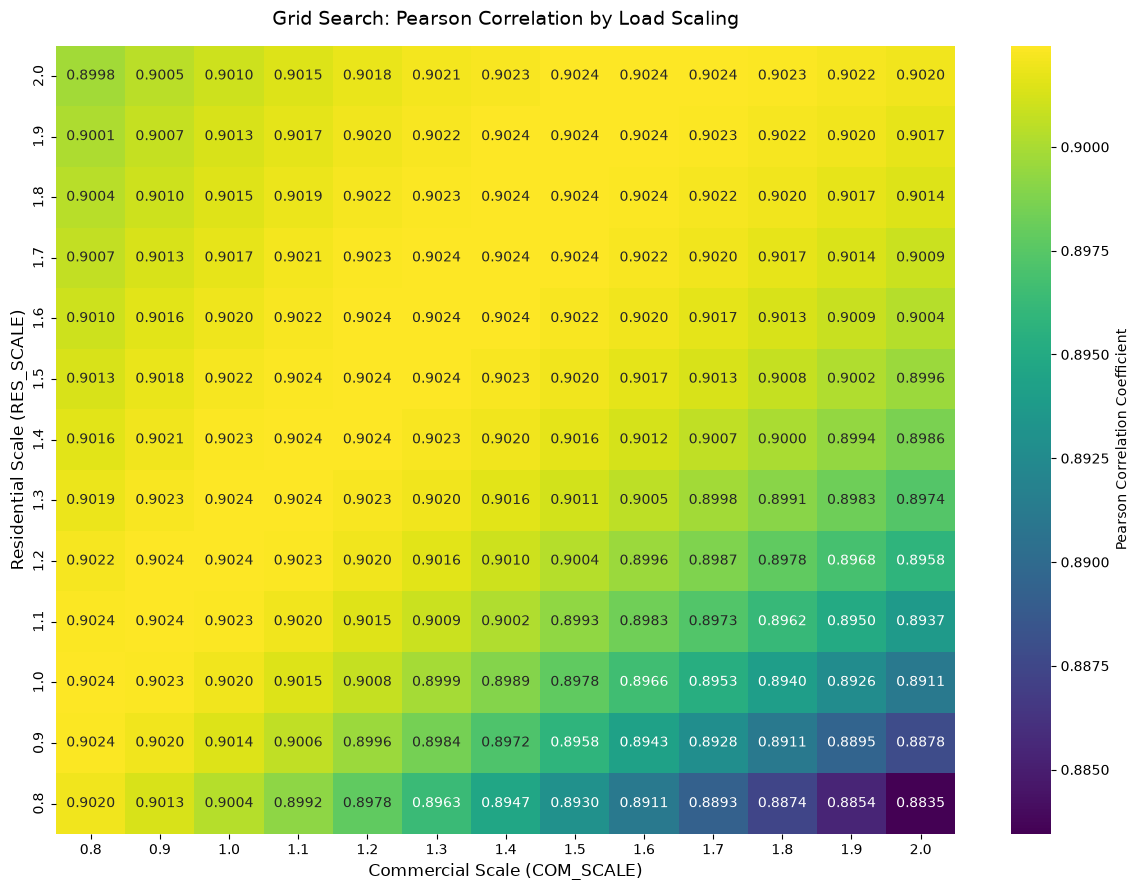

----------------------------------------
GRID SEARCH RESULTS:
Optimal Residential Scale: x1.6
Optimal Commercial Scale:  x1.3
Max Pearson Correlation:   0.90244
----------------------------------------


In [8]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

print("Running Grid Search for Optimal Scales (Pearson Correlation)...")

# --- 1. DEFINE SCALES ---
# Generate scales from 0.8 to 2.0 (inclusive) with 0.1 steps
# Using round() to avoid floating point weirdness (e.g., 0.80000000001)
scales = [round(x, 1) for x in np.arange(0.8, 2.1, 0.1)]

# --- 2. GET BASE UN-SCALED LOADS ---
# We use the raw profiles already in memory and slice to the common timeframe
base_res_mw = (res_profiles_df.sum(axis=1) / 1000).loc[common_start:common_end]
base_com_mw = (com_profiles_df.sum(axis=1) / 1000).loc[common_start:common_end]

# --- 3. CALCULATE MATRIX ---
# Initialize an empty DataFrame to hold the results
# Rows = RES_SCALE, Columns = COM_SCALE
results_matrix = pd.DataFrame(index=scales, columns=scales)

for r_scale in scales:
    for c_scale in scales:
        # Calculate total estimated shape (Industrial flat base doesn't affect Pearson, so we can omit it here)
        y_est_shape = (base_res_mw * r_scale) + (base_com_mw * c_scale)
        
        # Calculate Pearson Correlation
        corr = y_actual.corr(y_est_shape)
        
        # Store in matrix
        results_matrix.loc[r_scale, c_scale] = corr

# Convert matrix to float for seaborn
results_matrix = results_matrix.astype(float)

# --- 4. PLOT HEATMAP ---
plt.figure(figsize=(12, 9))

# Create the heatmap
# annot=True shows the numbers, cmap="viridis" gives a good color scale where brighter/yellow is higher
ax = sns.heatmap(results_matrix, annot=True, fmt=".4f", cmap="viridis", 
                 cbar_kws={'label': 'Pearson Correlation Coefficient'})

# Invert Y axis so 0.8 is at the bottom and 2.0 is at the top (feels more natural)
ax.invert_yaxis()

plt.title("Grid Search: Pearson Correlation by Load Scaling", fontsize=14, pad=15)
plt.xlabel("Commercial Scale (COM_SCALE)", fontsize=12)
plt.ylabel("Residential Scale (RES_SCALE)", fontsize=12)
plt.tight_layout()

plt.show()

# --- 5. FIND THE BEST COMBINATION ---
# Find the row and column index of the maximum value
best_res, best_com = results_matrix.stack().idxmax()
best_score = results_matrix.loc[best_res, best_com]

print("-" * 40)
print("GRID SEARCH RESULTS:")
print(f"Optimal Residential Scale: x{best_res}")
print(f"Optimal Commercial Scale:  x{best_com}")
print(f"Max Pearson Correlation:   {best_score:.5f}")
print("-" * 40)

#### Official recalibration (2026-08-30)

Applies the grid-search optimum found above to the `_featureeng` pipeline (the current best), and
compares against the old stale calibration (RES_SCALE=1.9, COM_SCALE=1.3 — found before the
weather-station fix, LightGBM switch, and lag-feature engineering, never re-run since) on the
same error metrics (MAE, RMSE), not just Pearson (which is near scale-invariant and barely moves).

ERCOT Actual Peak: 20,269.8 MW

OLD stale calibration (RES x1.9, COM x1.3, unchanged since before the weather-station/LightGBM/feature fixes):
  Peak Est (MW): 25,577.8
  Pearson: 0.9022
  MAE (MW): 2,116.7
  RMSE (MW): 2,625.4

NEW recalibration (RES x1.6, COM x1.3, grid-searched against the _featureeng pipeline):
  Peak Est (MW): 22,552.6
  Pearson: 0.9024
  MAE (MW): 1,201.4
  RMSE (MW): 1,550.9


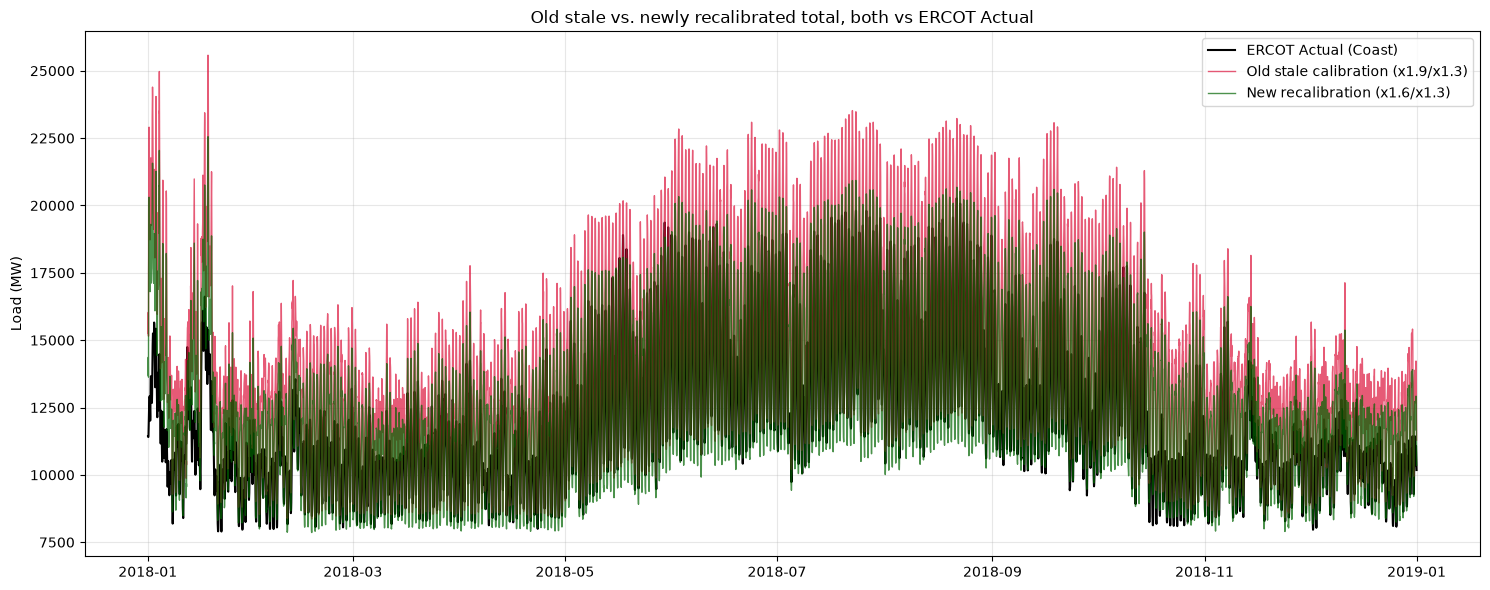


>>> UPDATED CALIBRATION FOR THE PAPER: RES_SCALE=1.6, COM_SCALE=1.3 <<<


In [9]:
best_res, best_com = results_matrix.stack().idxmax()

# --- Recalibrated (this pass) ---
y_new_cal = base_res_mw * best_res + base_com_mw * best_com + IND_BASE_MW

# --- Old stale calibration (pre weather-fix/LightGBM/feature-engineering, kept for comparison) ---
y_old_cal = base_res_mw * 1.9 + base_com_mw * 1.3 + IND_BASE_MW

def error_stats(y_true, y_pred):
    err = y_true - y_pred
    return {
        "Peak Est (MW)": y_pred.max(),
        "Pearson": y_true.corr(y_pred),
        "MAE (MW)": err.abs().mean(),
        "RMSE (MW)": np.sqrt((err ** 2).mean()),
    }

print(f"ERCOT Actual Peak: {y_actual.max():,.1f} MW\n")
print(f"OLD stale calibration (RES x1.9, COM x1.3, unchanged since before the weather-station/LightGBM/feature fixes):")
for k, v in error_stats(y_actual, y_old_cal).items():
    print(f"  {k}: {v:,.4f}" if "Pearson" in k else f"  {k}: {v:,.1f}")

print(f"\nNEW recalibration (RES x{best_res}, COM x{best_com}, grid-searched against the _featureeng pipeline):")
for k, v in error_stats(y_actual, y_new_cal).items():
    print(f"  {k}: {v:,.4f}" if "Pearson" in k else f"  {k}: {v:,.1f}")

fig, ax = plt.subplots(figsize=(15, 6))
ax.plot(y_actual.index, y_actual, color='black', linewidth=1.5, label='ERCOT Actual (Coast)')
ax.plot(y_old_cal.index, y_old_cal, color='crimson', linewidth=1, alpha=0.7, label=f'Old stale calibration (x1.9/x1.3)')
ax.plot(y_new_cal.index, y_new_cal, color='darkgreen', linewidth=1, alpha=0.7, label=f'New recalibration (x{best_res}/x{best_com})')
ax.set_ylabel("Load (MW)")
ax.set_title("Old stale vs. newly recalibrated total, both vs ERCOT Actual")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"\n>>> UPDATED CALIBRATION FOR THE PAPER: RES_SCALE={best_res}, COM_SCALE={best_com} <<<")